[*********************100%***********************]  10 of 10 completed

正在从 yfinance 下载股票历史数据...
数据加载完成！有效公共交易日天数: 751

【主成分特征值与方差解释率表】
      特征值 (Eigenvalue)  方差解释率 (%)  累计解释率 (%)
PC1           0.000859  33.262898  33.262898
PC2           0.000424  16.406950  49.669848
PC3           0.000307  11.883865  61.553713
PC4           0.000220   8.527572  70.081285
PC5           0.000184   7.108824  77.190109
PC6           0.000167   6.460997  83.651106
PC7           0.000152   5.903547  89.554653
PC8           0.000114   4.405605  93.960258
PC9           0.000084   3.235480  97.195738
PC10          0.000072   2.804262 100.000000

【前 3 个主成分对应的特征向量 (因子载荷)】
                       Sector  PC1 (市场整体)  PC2 (风格分化)  PC3 (行业轮动)
AAPL         Information Tech   -0.347744   -0.037863    0.265891
JPM                Financials   -0.288514   -0.192863   -0.189030
JNJ                Healthcare   -0.002955   -0.259127    0.180442
AMZN   Consumer Discretionary   -0.542999    0.349546    0.204838
PG           Consumer Staples   -0.032045   -0.198791    0.306059
XOM                

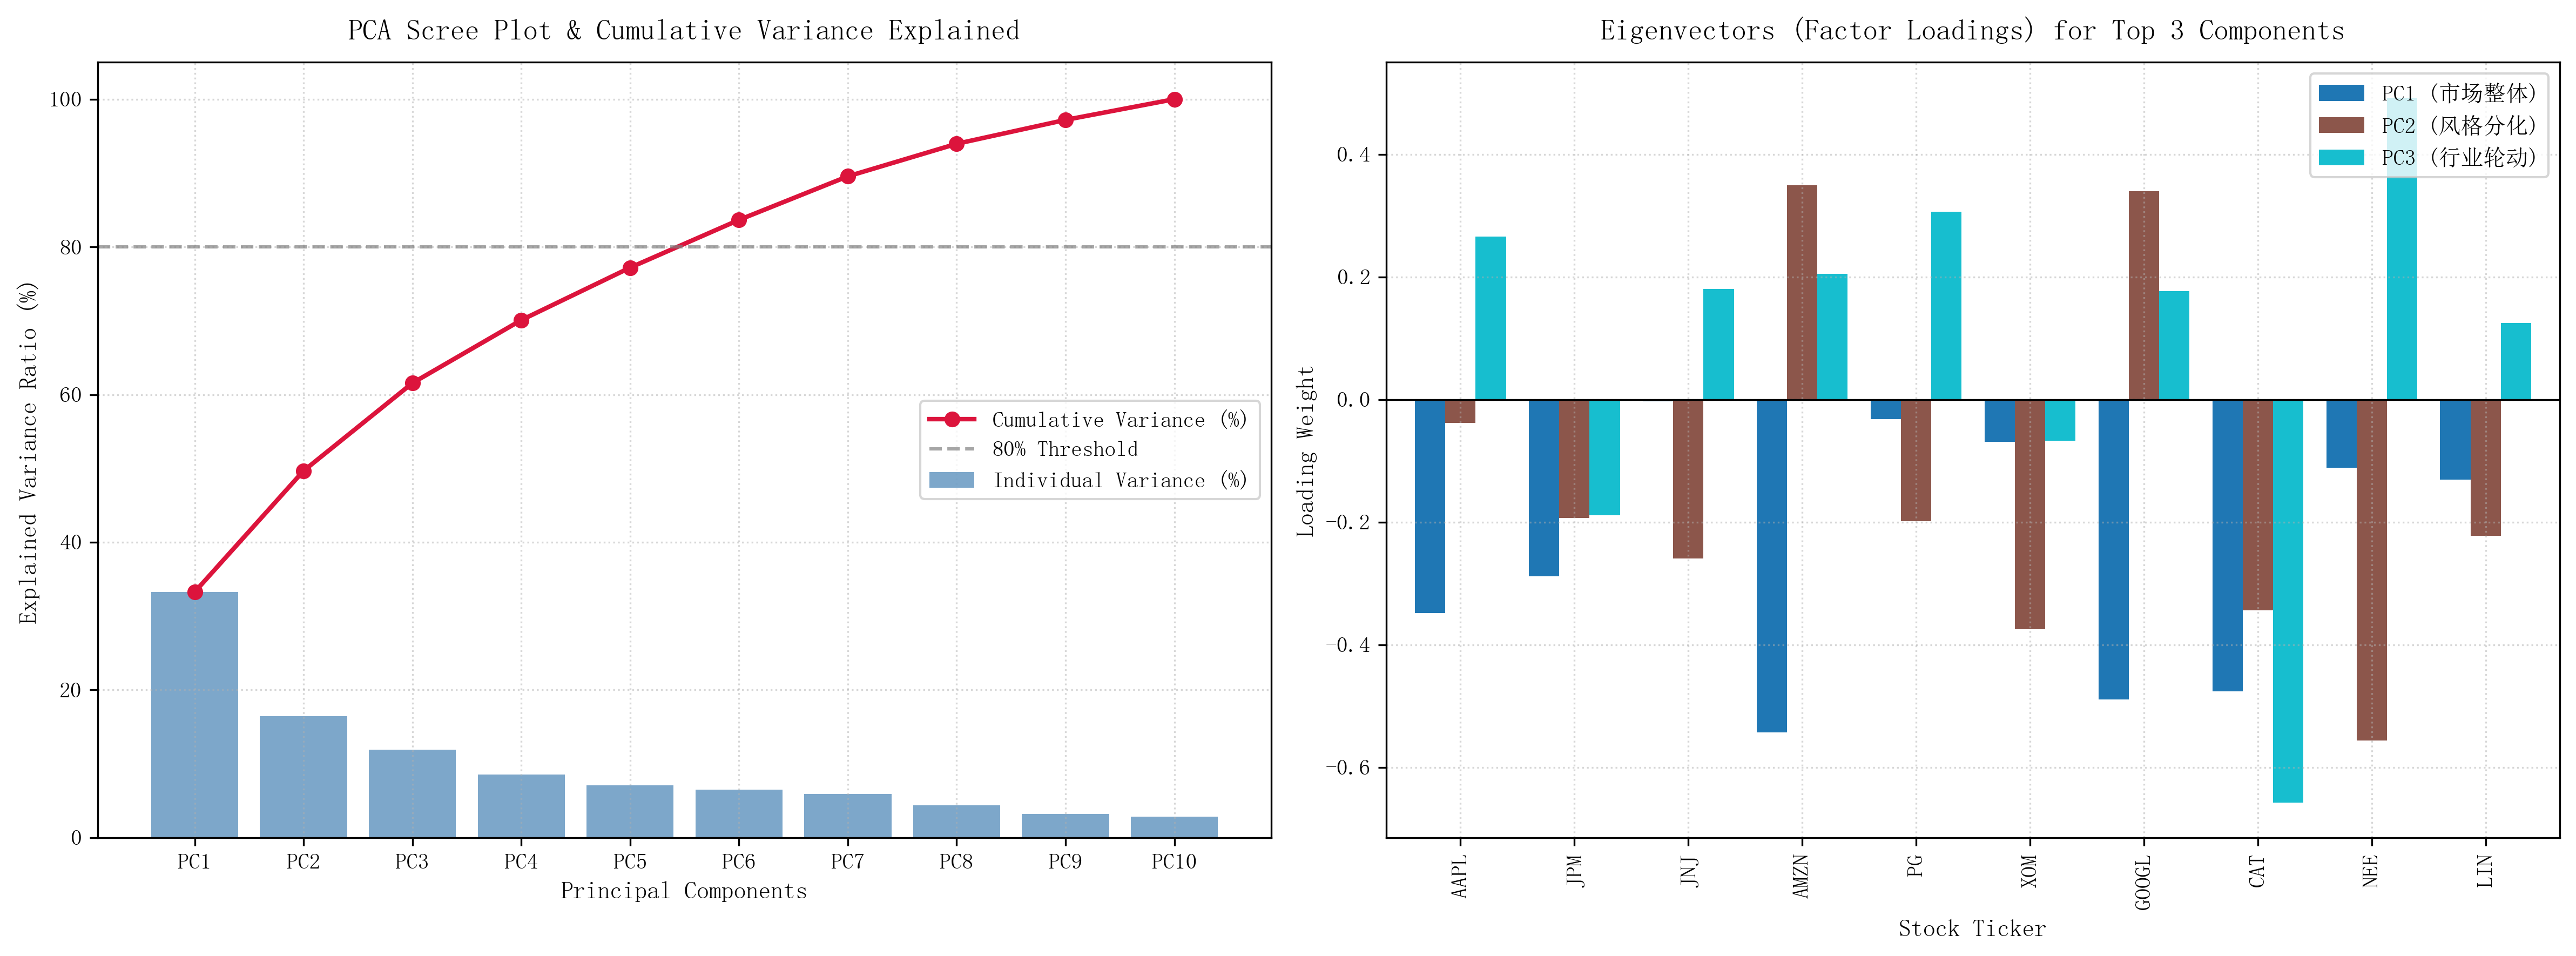

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

# 设置显示格式与字体
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.6f" % x)
plt.rcParams["font.sans-serif"] = ["Simsun"]
plt.rcParams["axes.unicode_minus"] = False

# =====================================================================
# 1. 选取 10 只分属不同行业的代表性股票并下载历史数据 (3年区间)
# =====================================================================
tickers_dict = {
    "AAPL": "Information Tech",
    "JPM": "Financials",
    "JNJ": "Healthcare",
    "AMZN": "Consumer Discretionary",
    "PG": "Consumer Staples",
    "XOM": "Energy",
    "GOOGL": "Communication Services",
    "CAT": "Industrials",
    "NEE": "Utilities",
    "LIN": "Materials",
}

stock_list = list(tickers_dict.keys())
tickers_str = " ".join(stock_list)

print("正在从 yfinance 下载股票历史数据...")
raw_data = yf.download(
    tickers_str, start="2023-08-31", end="2026-08-31", auto_adjust=True
)

if "Close" in raw_data.columns.levels[0]:
    close_prices = raw_data["Close"][stock_list].dropna()
else:
    close_prices = raw_data[stock_list].dropna()

print(f"数据加载完成！有效公共交易日天数: {len(close_prices)}")

# 计算日对数收益率 R_t = ln(S_t) - ln(S_{t-1})
returns_df = np.log(close_prices / close_prices.shift(1)).dropna()

# 样本协方差矩阵 Sigma
Sigma_matrix = returns_df.cov()

# =====================================================================
# 2. 对协方差矩阵进行主成分分析 (PCA)
# =====================================================================
# (1) 谱分解: 对称矩阵的特征值与特征向量求解
eigenvalues, eigenvectors = np.linalg.eigh(Sigma_matrix.values)

# eigh 默认升序，需翻转为降序 (从最大主成分到最小)
idx_sorted = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx_sorted]
eigenvectors = eigenvectors[:, idx_sorted]

# (2) 计算各主成分方差解释率与累计方差解释率
total_variance = np.sum(eigenvalues)
var_explained = eigenvalues / total_variance
cum_var_explained = np.cumsum(var_explained)

# (3) 整理主成分特征值与方差贡献度表
pc_labels = [f"PC{i+1}" for i in range(len(stock_list))]
pca_summary_df = pd.DataFrame(
    {
        "特征值 (Eigenvalue)": eigenvalues,
        "方差解释率 (%)": var_explained * 100,
        "累计解释率 (%)": cum_var_explained * 100,
    },
    index=pc_labels,
)

print("\n" + "=" * 75)
print("【主成分特征值与方差解释率表】")
print("=" * 75)
print(pca_summary_df)

# (4) 整理各股票在前 3 个主成分上的载荷 (Eigenvectors / Factor Loadings)
loadings_df = pd.DataFrame(
    eigenvectors[:, :3],
    index=stock_list,
    columns=["PC1 (市场整体)", "PC2 (风格分化)", "PC3 (行业轮动)"],
)
loadings_df["Sector"] = [tickers_dict[t] for t in stock_list]

print("\n" + "=" * 75)
print("【前 3 个主成分对应的特征向量 (因子载荷)】")
print("=" * 75)
print(loadings_df[["Sector", "PC1 (市场整体)", "PC2 (风格分化)", "PC3 (行业轮动)"]])

# =====================================================================
# 3. 结果可视化：碎石图与前3主成分因子载荷图
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# 图1: 碎石图 (Scree Plot) - 累计贡献率
axes[0].bar(
    pc_labels,
    var_explained * 100,
    color="steelblue",
    alpha=0.7,
    label="Individual Variance (%)",
)
axes[0].plot(
    pc_labels,
    cum_var_explained * 100,
    color="crimson",
    marker="o",
    linewidth=2,
    label="Cumulative Variance (%)",
)
axes[0].axhline(80, color="grey", linestyle="--", alpha=0.7, label="80% Threshold")
axes[0].set_title(
    "PCA Scree Plot & Cumulative Variance Explained", fontsize=13, pad=10
)
axes[0].set_ylabel("Explained Variance Ratio (%)", fontsize=11)
axes[0].set_xlabel("Principal Components", fontsize=11)
axes[0].legend(loc="center right")
axes[0].grid(True, linestyle=":", alpha=0.5)

# 图2: 前3主成分特征向量权重条形图
loadings_plot_data = loadings_df[
    ["PC1 (市场整体)", "PC2 (风格分化)", "PC3 (行业轮动)"]
]
loadings_plot_data.plot(kind="bar", ax=axes[1], width=0.8, colormap="tab10")
axes[1].axhline(0, color="black", linestyle="-", linewidth=0.8)
axes[1].set_title(
    "Eigenvectors (Factor Loadings) for Top 3 Components", fontsize=13, pad=10
)
axes[1].set_ylabel("Loading Weight", fontsize=11)
axes[1].set_xlabel("Stock Ticker", fontsize=11)
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

正在读取企业债历史估值数据...
  2280354.IB (AA+): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280373.IB (AA+): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2480042.IB (AA+): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280047.IB (AA): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280319.IB (AA): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280323.IB (AA): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280444.IB (AA): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2380101.IB (AA): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280313.IB (AA-): 247 个交易日, 2025-10-09 ~ 2026-09-30
  2280420.IB (AA-): 247 个交易日, 2025-10-09 ~ 2026-09-30

共同月末观测点数: 12 (2025-10 ~ 2026-09)

【月末估价收益率（%）】
         2280354.IB  2280373.IB  2480042.IB  2280047.IB  2280319.IB  2280323.IB  2280444.IB  2380101.IB  2280313.IB  2280420.IB
月份                                                                                                                             
2025-10    1.806400    1.860800    2.011700    1.904900    2.599400    1.928200    2.139900    2.524700    2.493300    2.432500
2025-11    1.847

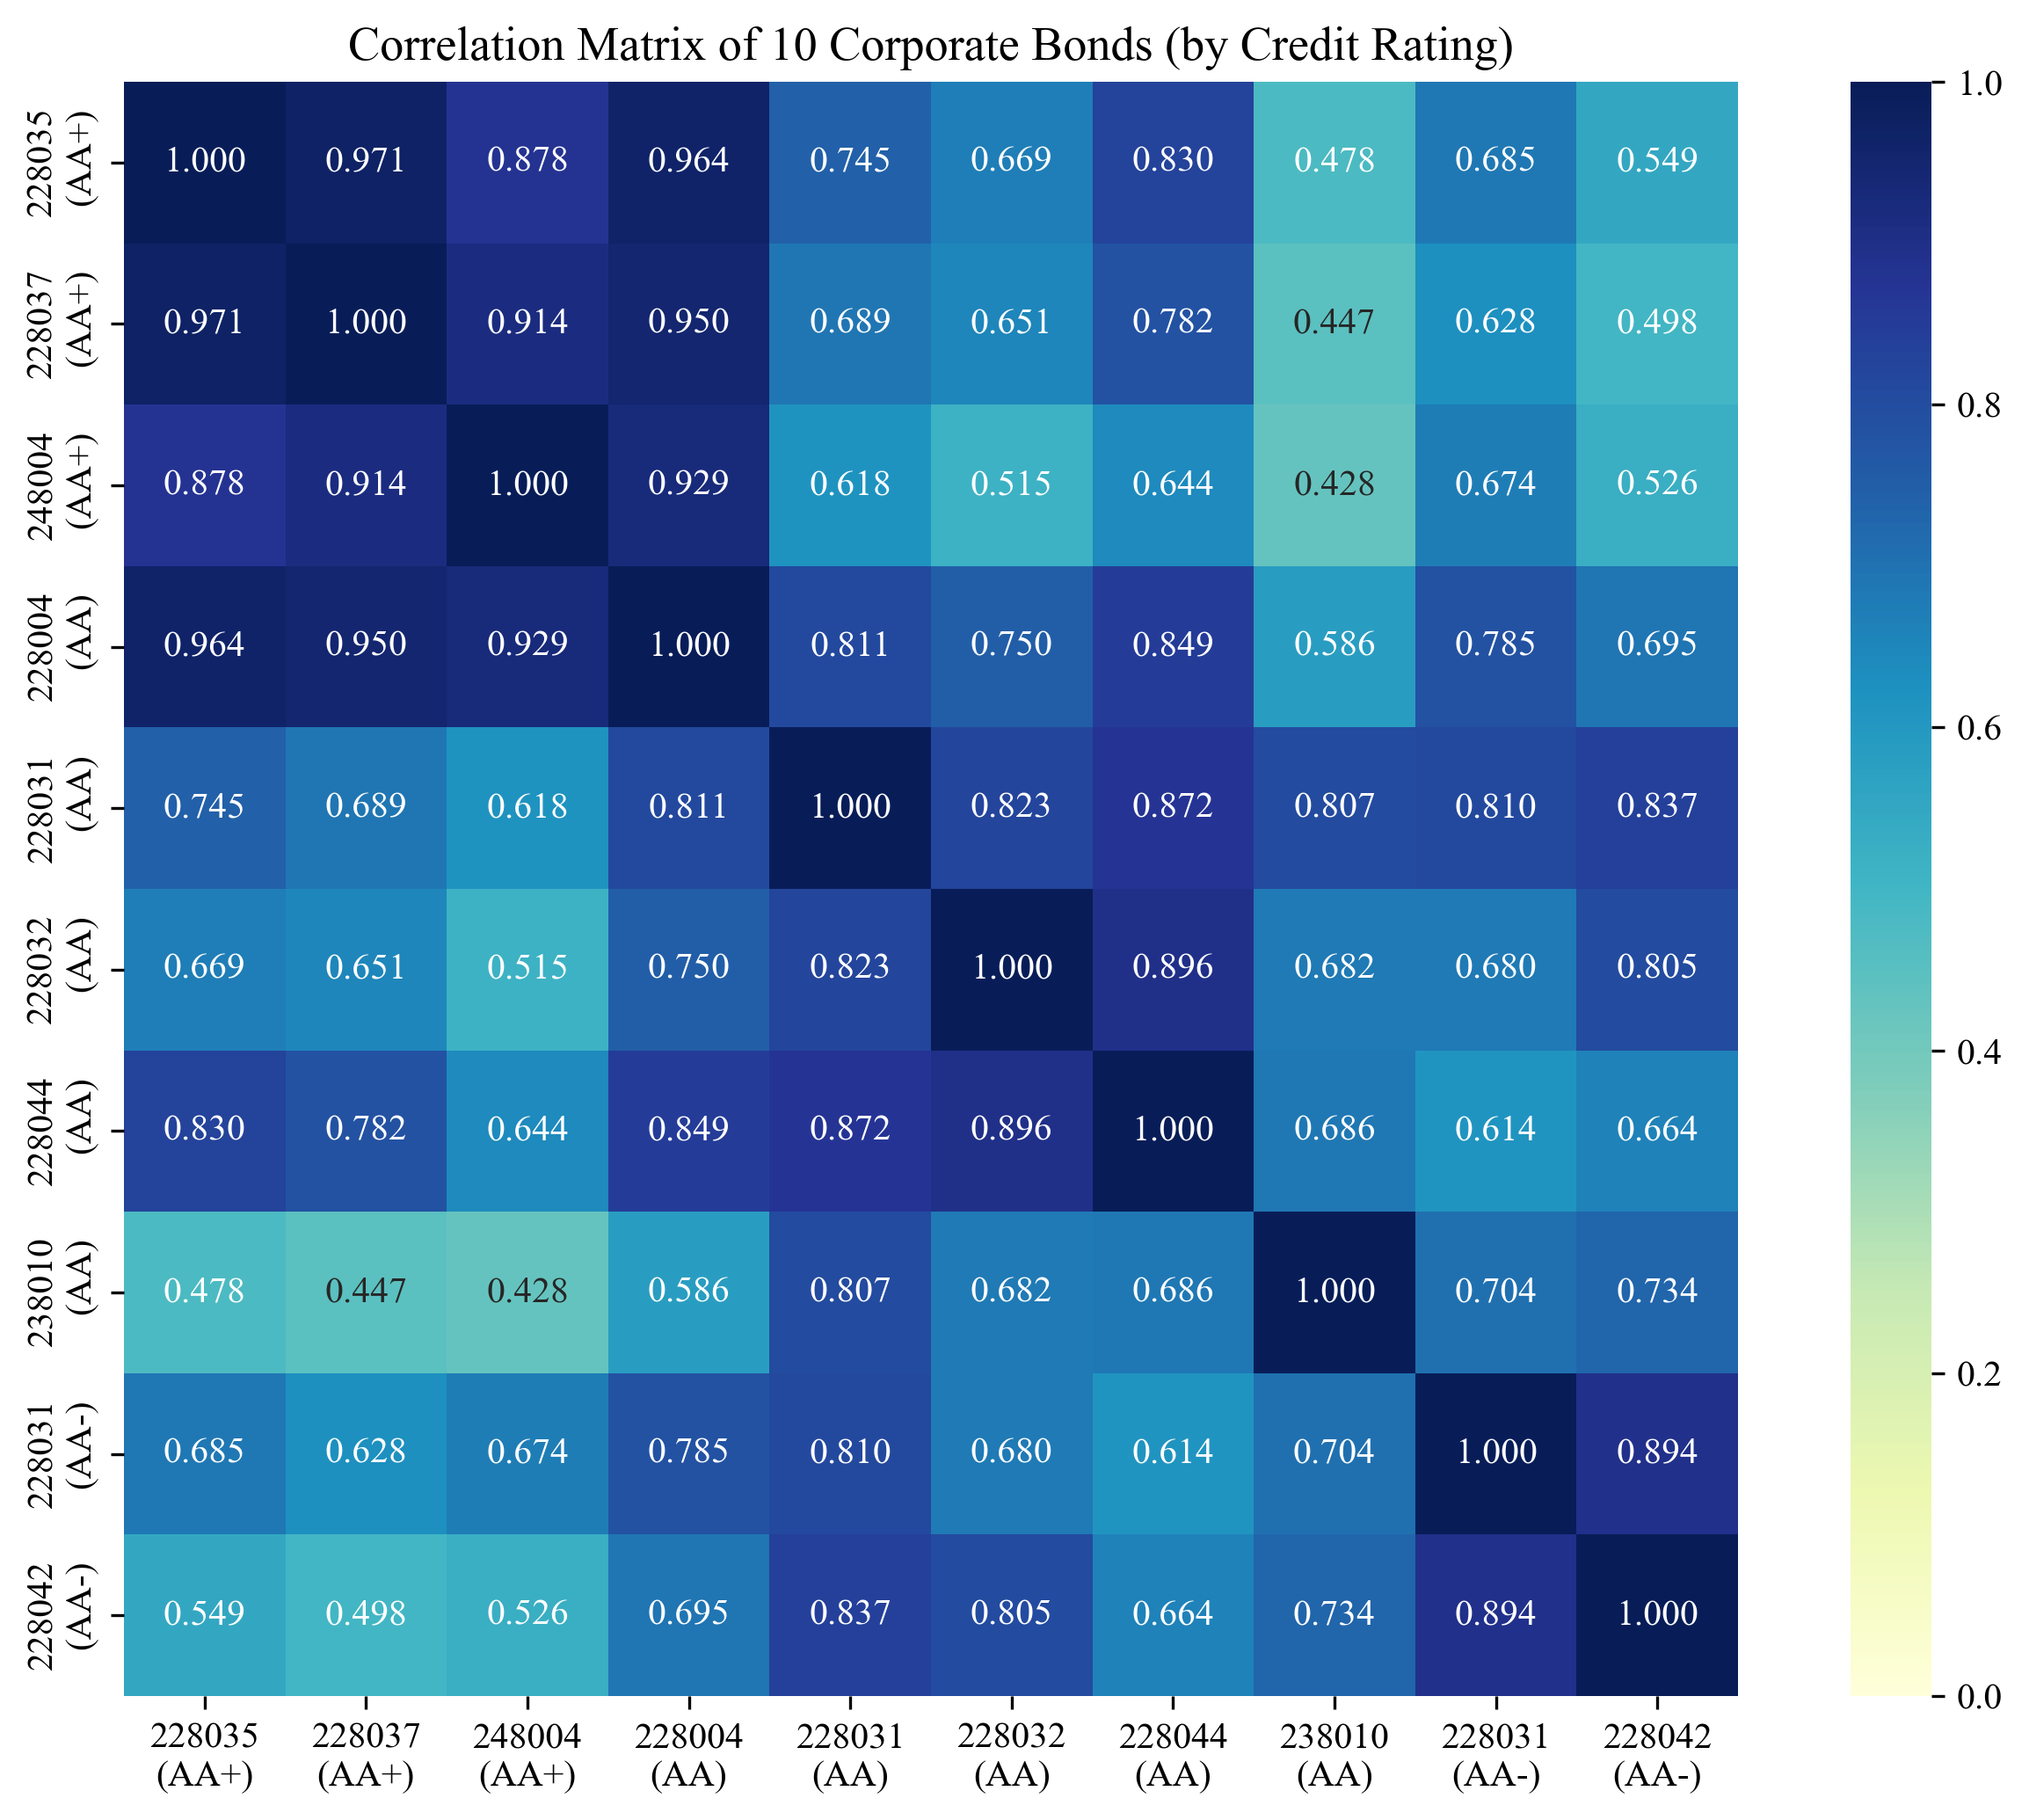


【协方差矩阵主成分分析（PCA）—— 特征值与方差解释率】
    主成分      特征值  特征值(×10⁻⁴)    方差解释率  累计方差解释率
0   PC1 0.000006    0.064874 0.725350 0.725350
1   PC2 0.000001    0.013153 0.147058 0.872407
2   PC3 0.000000    0.004891 0.054683 0.927090
3   PC4 0.000000    0.004006 0.044793 0.971883
4   PC5 0.000000    0.001192 0.013323 0.985206
5   PC6 0.000000    0.000792 0.008852 0.994058
6   PC7 0.000000    0.000269 0.003007 0.997065
7   PC8 0.000000    0.000231 0.002581 0.999646
8   PC9 0.000000    0.000025 0.000281 0.999927
9  PC10 0.000000    0.000007 0.000073 1.000000

【因子载荷矩阵（特征向量 × √特征值）】
                       PC1       PC2       PC3       PC4       PC5       PC6       PC7       PC8       PC9      PC10
2280354.IB (AA+) -0.000500 -0.000300  0.000100  0.000100 -0.000100 -0.000100 -0.000000 -0.000100  0.000000 -0.000000
2280373.IB (AA+) -0.000600 -0.000400  0.000100  0.000000 -0.000000 -0.000100 -0.000100  0.000000 -0.000000  0.000000
2480042.IB (AA+) -0.001000 -0.000700 -0.000100 -0.000200  0.000100  0.000100  

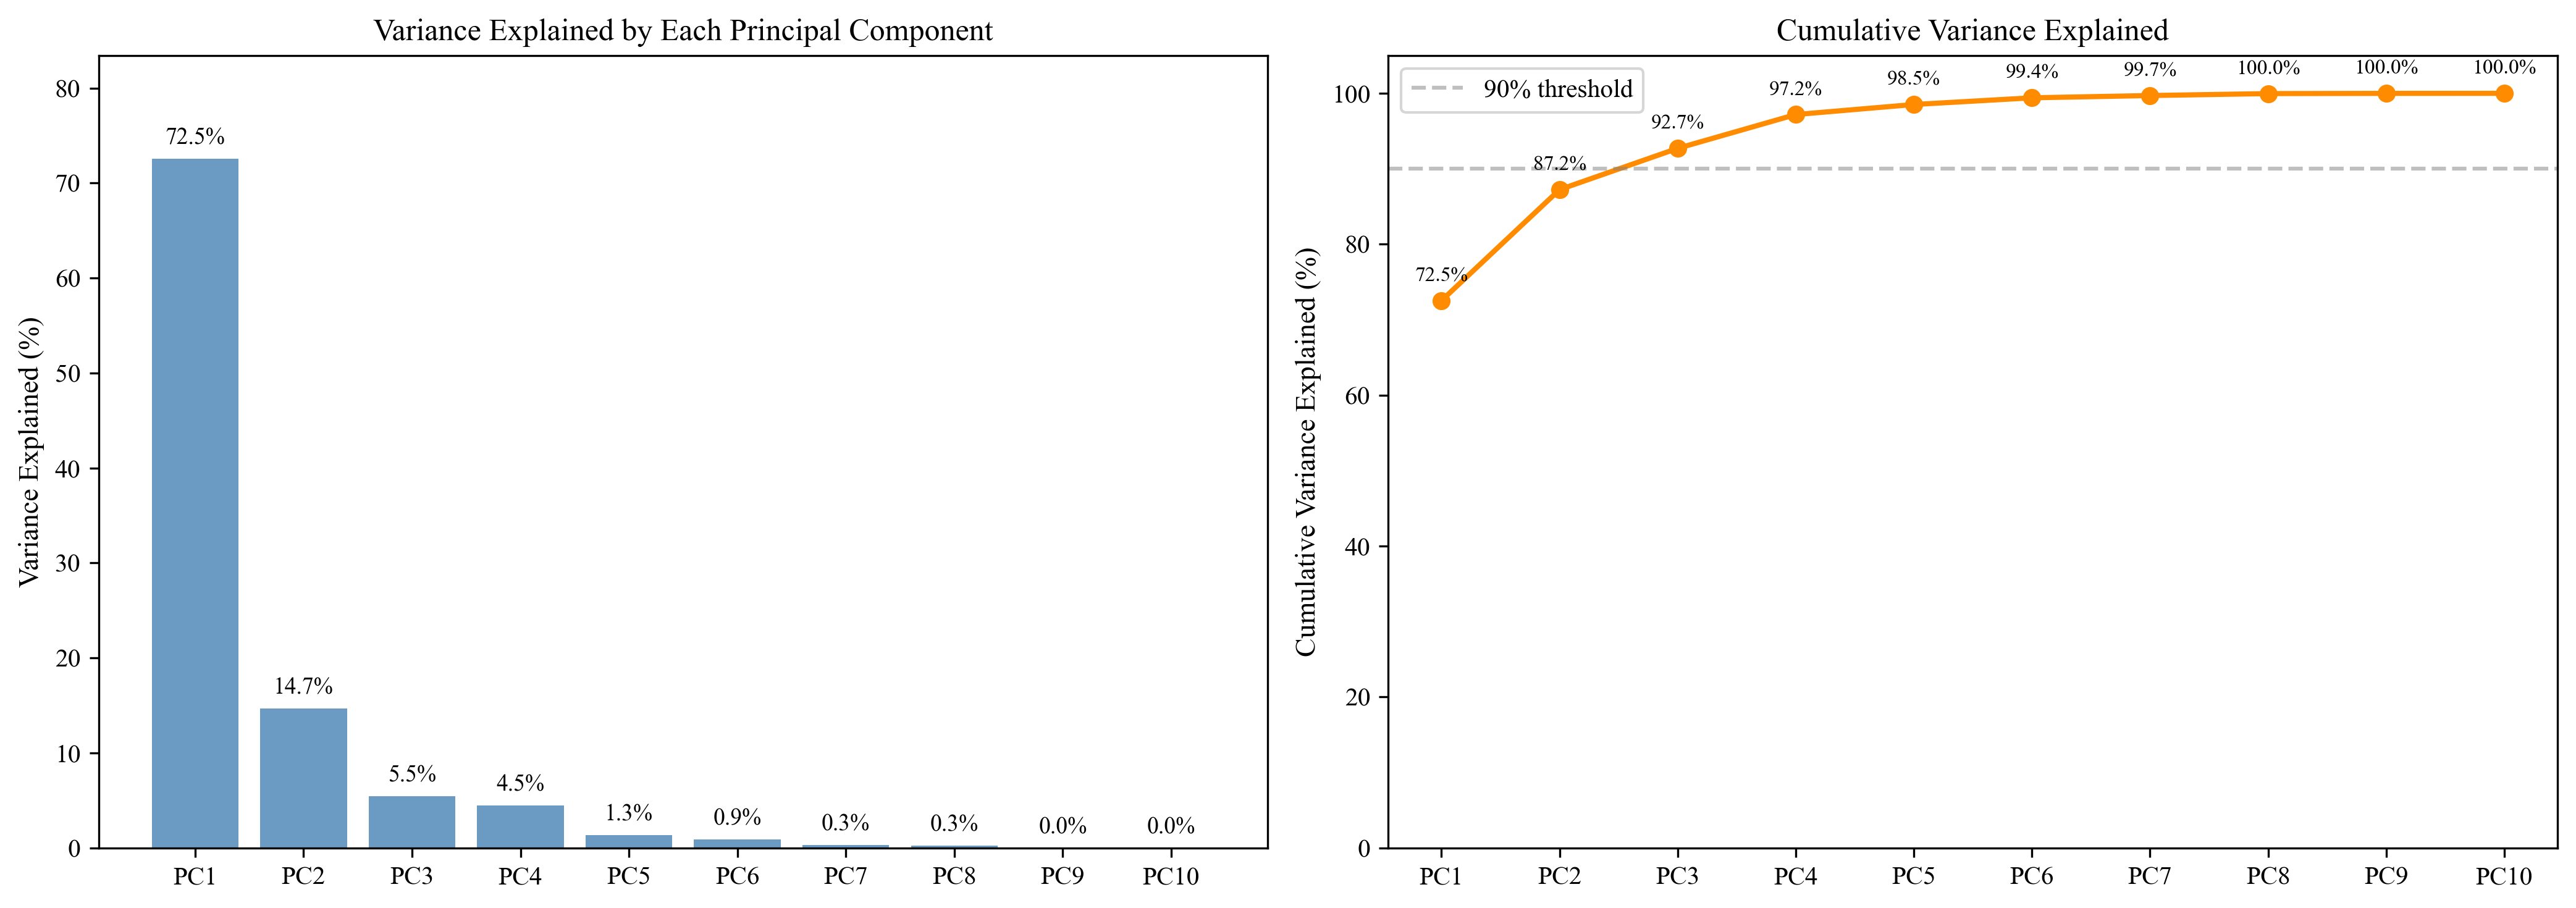

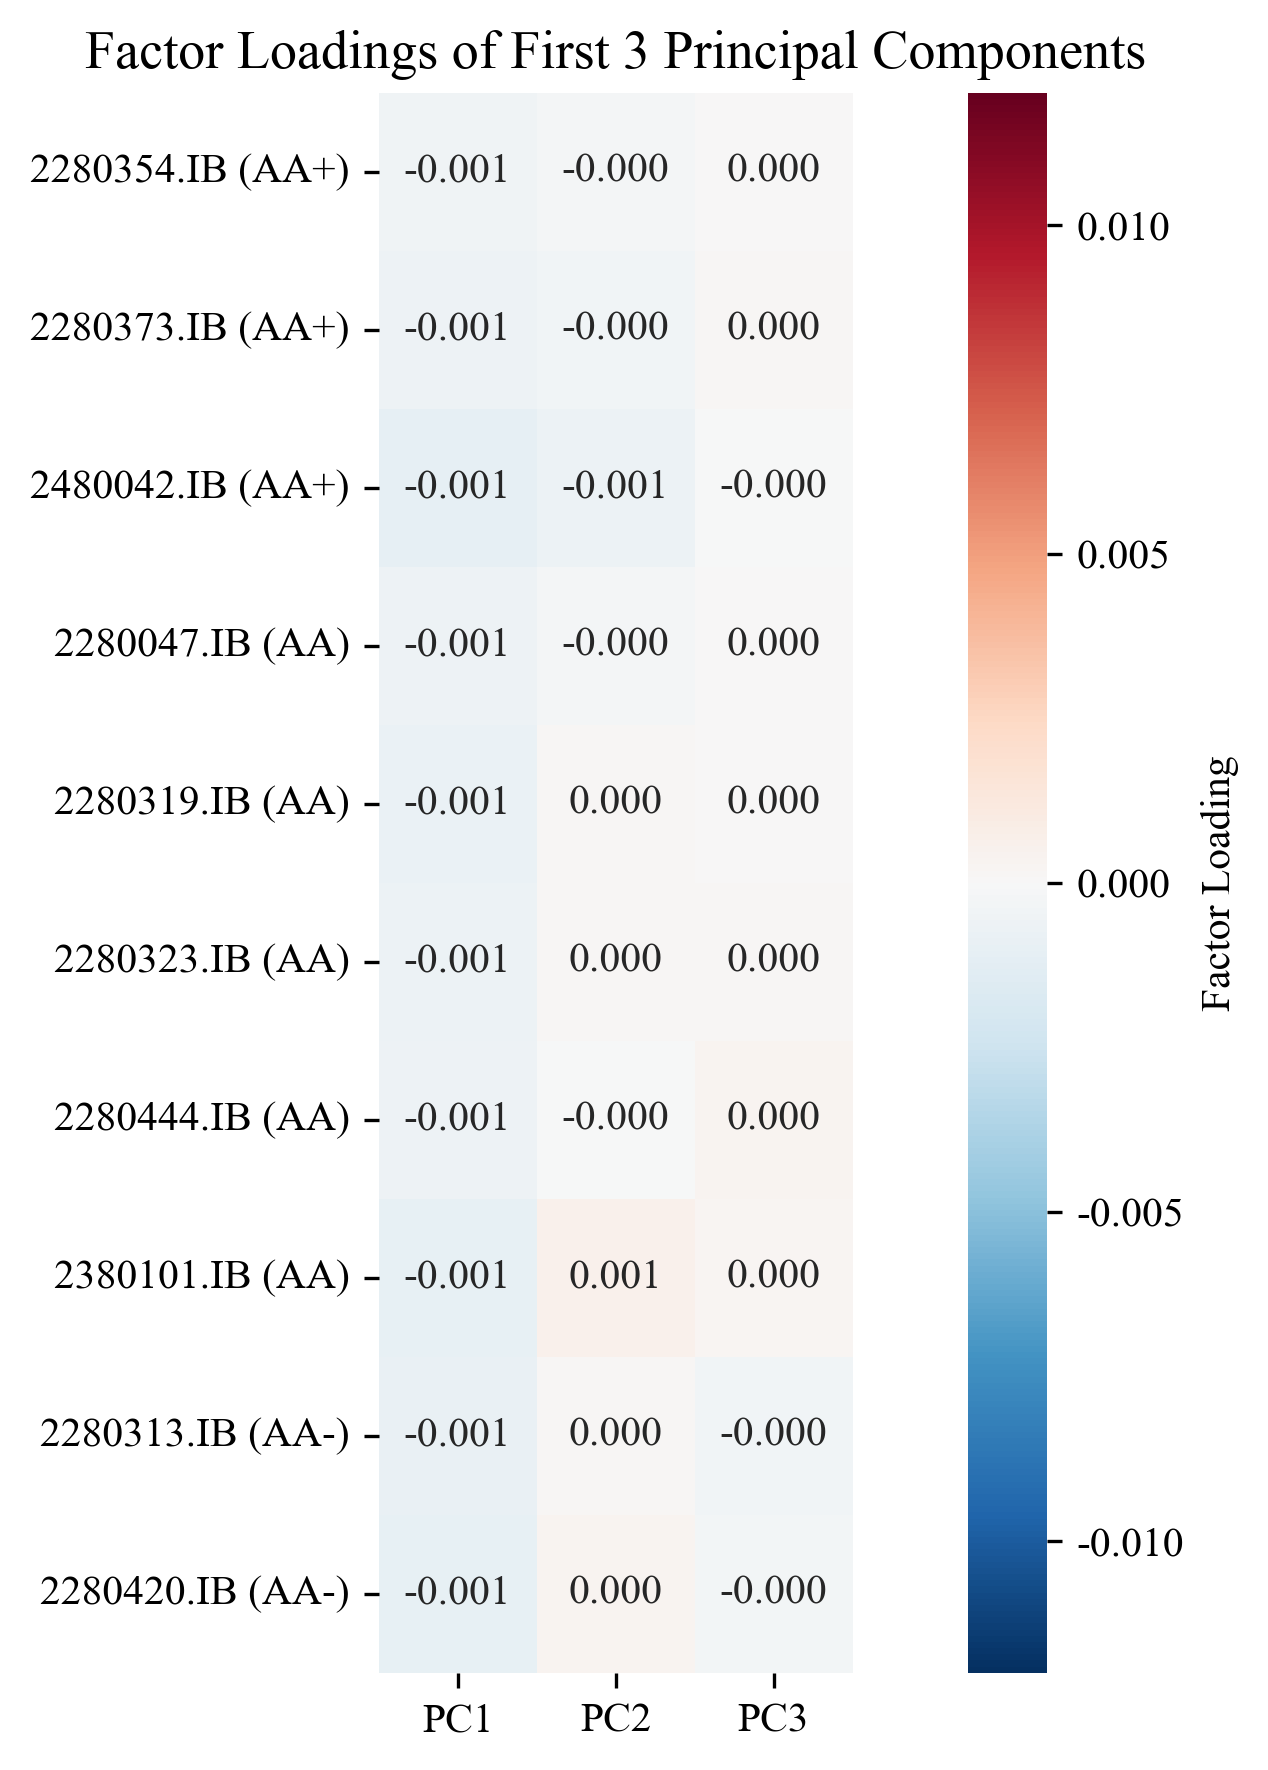


【债券投资组合分析 — 结果汇总】
债券数量: 10 支（AA+×3, AA×5, AA-×2）
数据区间: 2025-10 ~ 2026-09（12个月末观测点）
月收益率样本数: 11 个月

协方差矩阵维度: 10 × 10

PCA 结果:
  PC1 (水平因子): 方差解释率 = 72.53%
  PC2 (信用利差因子): 方差解释率 = 14.71%
  PC3 (曲率因子): 方差解释率 = 5.47%
  前3个主成分累计方差解释率 = 92.71%
  前5个主成分累计方差解释率 = 98.52%


In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from openpyxl import load_workbook

warnings.filterwarnings("ignore")

# 设置显示格式与字体
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.6f" % x)
plt.rcParams["font.sans-serif"] = ["Times New Roman"]
plt.rcParams["axes.unicode_minus"] = False

# =====================================================================
# 1. 选取 10 支分属不同信用等级的企业债券并读取历史数据
# =====================================================================
# 数据文件夹路径（中债DQ导出的日度估值表）
DATA_FOLDER = r"D:\0000 ObsidianNotes\Grade1-Course\风险管理\CorporateBond"

# 10 支企业债：AA+ × 3，AA × 5，AA- × 2
# 每支债券对应一个 Excel 文件（文件名格式：代码 评级.xlsx）
bonds_info = [
    {"code": "2280354.IB", "rating": "AA+", "file": "2280354.IB AA+.xlsx"},
    {"code": "2280373.IB", "rating": "AA+", "file": "2280373.IB AA+.xlsx"},
    {"code": "2480042.IB", "rating": "AA+", "file": "2480042.IB AA+.xlsx"},
    {"code": "2280047.IB", "rating": "AA",  "file": "2280047.IB AA.xlsx"},
    {"code": "2280319.IB", "rating": "AA",  "file": "2280319.IB AA.xlsx"},
    {"code": "2280323.IB", "rating": "AA",  "file": "2280323.IB AA.xlsx"},
    {"code": "2280444.IB", "rating": "AA",  "file": "2280444.IB AA.xlsx"},
    {"code": "2380101.IB", "rating": "AA",  "file": "2380101.IB AA.xlsx"},
    {"code": "2280313.IB", "rating": "AA-", "file": "2280313.IB AA-.xlsx"},
    {"code": "2280420.IB", "rating": "AA-", "file": "2280420.IB AA-.xlsx"},
]

bond_codes = [b["code"] for b in bonds_info]
bond_ratings = [b["rating"] for b in bonds_info]


def read_bond_valuation(filepath):
    """
    读取单支债券的中债DQ日度估值Excel表，返回按日期升序排列的 DataFrame。
    提取字段：估值日期、估价收益率(%)、估价修正久期、估价凸性、估价净价、中债隐含评级
    """
    wb = load_workbook(filepath, data_only=True)
    ws = wb.active

    # 建立列名 → 列索引映射（不同导出文件列顺序可能不同）
    col_map = {}
    for c in range(1, ws.max_column + 1):
        header = ws.cell(row=1, column=c).value
        if header:
            col_map[str(header).strip()] = c

    # 定位关键字段列
    date_col = col_map.get("估值日期") or col_map.get("日期")
    yld_col = col_map.get("估价收益率(%)") or col_map.get("估价收益率（%）")
    dur_col = col_map.get("估价修正久期")
    conv_col = col_map.get("估价凸性")
    px_col = col_map.get("估价净价")
    rtg_col = col_map.get("中债隐含评级")

    records = []
    for r in range(2, ws.max_row + 1):
        d = ws.cell(row=r, column=date_col).value
        if d is None:
            continue
        # 统一日期格式
        if isinstance(d, str):
            d = pd.to_datetime(d[:10]).date()
        elif hasattr(d, "date"):
            d = d.date()

        y = ws.cell(row=r, column=yld_col).value if yld_col else None
        dur = ws.cell(row=r, column=dur_col).value if dur_col else None
        conv = ws.cell(row=r, column=conv_col).value if conv_col else 0.0
        px = ws.cell(row=r, column=px_col).value if px_col else None
        rtg = ws.cell(row=r, column=rtg_col).value if rtg_col else None

        if y is not None and dur is not None:
            records.append({
                "date": d,
                "yield": float(y),
                "duration": float(dur),
                "convexity": float(conv) if conv else 0.0,
                "price": float(px) if px else np.nan,
                "implied_rating": rtg,
            })

    df = pd.DataFrame(records).sort_values("date").reset_index(drop=True)
    return df


# 读取全部 10 支债券的日度数据
print("正在读取企业债历史估值数据...")
bond_daily = {}
for b in bonds_info:
    fpath = os.path.join(DATA_FOLDER, b["file"])
    bond_daily[b["code"]] = read_bond_valuation(fpath)
    print(f"  {b['code']} ({b['rating']}): "
          f"{len(bond_daily[b['code']])} 个交易日, "
          f"{bond_daily[b['code']]['date'].iloc[0]} ~ {bond_daily[b['code']]['date'].iloc[-1]}")


# =====================================================================
# 2. 提取月末数据，计算月收益率
# =====================================================================
def extract_month_end(df):
    """从日度数据中提取每月最后一个交易日的观测值"""
    df = df.copy()
    df["year_month"] = df["date"].apply(lambda d: (d.year, d.month))
    # 每月取日期最大的一行（即最后一个交易日）
    idx = df.groupby("year_month")["date"].idxmax()
    me = df.loc[idx].sort_values("date").reset_index(drop=True)
    return me


# 提取每支债券的月末数据
bond_month_end = {}
for code in bond_codes:
    bond_month_end[code] = extract_month_end(bond_daily[code])

# 对齐所有债券的共同月份
all_months = set()
for code in bond_codes:
    for _, row in bond_month_end[code].iterrows():
        all_months.add((row["date"].year, row["date"].month))
common_months = sorted(all_months)
month_labels = [f"{y}-{m:02d}" for (y, m) in common_months]
n_months = len(common_months)

print(f"\n共同月末观测点数: {n_months} ({month_labels[0]} ~ {month_labels[-1]})")

# 构建月末收益率矩阵 Y (n_months × 10) 和久期矩阵 D
Y = np.full((n_months, len(bond_codes)), np.nan)
D = np.full((n_months, len(bond_codes)), np.nan)
Conv = np.full((n_months, len(bond_codes)), np.nan)
P = np.full((n_months, len(bond_codes)), np.nan)

for j, code in enumerate(bond_codes):
    me = bond_month_end[code]
    me_dict = {(row["date"].year, row["date"].month): row for _, row in me.iterrows()}
    for i, m in enumerate(common_months):
        if m in me_dict:
            Y[i, j] = me_dict[m]["yield"]
            D[i, j] = me_dict[m]["duration"]
            Conv[i, j] = me_dict[m]["convexity"]
            P[i, j] = me_dict[m]["price"]

# 月末收益率 DataFrame
yield_df = pd.DataFrame(Y, index=month_labels, columns=bond_codes)
yield_df.index.name = "月份"

# 月末修正久期 DataFrame
duration_df = pd.DataFrame(D, index=month_labels, columns=bond_codes)
duration_df.index.name = "月份"

print("\n" + "=" * 70)
print("【月末估价收益率（%）】")
print("=" * 70)
print(yield_df.round(4))

# ---- 计算月收益率 ----
# 久期-凸性近似公式：
#   r_t = -D_{t-1} * Δy_t + 0.5 * Convexity_{t-1} * (Δy_t)^2
# 其中 Δy_t = (y_t - y_{t-1}) / 100  （收益率从百分数转为小数）
n_returns = n_months - 1
R = np.full((n_returns, len(bond_codes)), np.nan)

for i in range(1, n_months):
    for j in range(len(bond_codes)):
        if not (np.isnan(Y[i, j]) or np.isnan(Y[i - 1, j]) or np.isnan(D[i - 1, j])):
            dy = (Y[i, j] - Y[i - 1, j]) / 100.0  # 转为小数
            d_prev = D[i - 1, j]
            cv_prev = Conv[i - 1, j] if not np.isnan(Conv[i - 1, j]) else 0.0
            R[i - 1, j] = -d_prev * dy + 0.5 * cv_prev * dy ** 2

ret_labels = month_labels[1:]  # 11 个月
returns_df = pd.DataFrame(R, index=ret_labels, columns=bond_codes)
returns_df.index.name = "月份"

print("\n" + "=" * 70)
print("【月收益率（久期-凸性近似）】")
print("=" * 70)
print(returns_df.round(6))

# 各债券月收益率统计
mu_bond = returns_df.mean()
var_bond = returns_df.var()
std_bond = returns_df.std()

bond_stats = pd.DataFrame({
    "信用评级": bond_ratings,
    "均值 mu": mu_bond,
    "方差 sigma^2": var_bond,
    "波动率 sigma": std_bond,
}, index=bond_codes)

print("\n" + "=" * 70)
print("【各企业债月收益率的期望、方差与波动率】")
print("=" * 70)
print(bond_stats)


# =====================================================================
# 3. 计算协方差矩阵与相关系数矩阵
# =====================================================================
Sigma_bond = returns_df.cov()   # 协方差矩阵
Corr_bond = returns_df.corr()   # 相关系数矩阵

print("\n" + "=" * 70)
print("【月收益率协方差矩阵（×10⁻⁴）】")
print("=" * 70)
print((Sigma_bond * 1e4).round(4))

print("\n" + "=" * 70)
print("【月收益率相关系数矩阵】")
print("=" * 70)
print(Corr_bond.round(4))

# 绘制相关系数热力图
plt.figure(figsize=(9, 7), dpi=300)
sns.heatmap(
    Corr_bond,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0.0,
    vmax=1.0,
    square=True,
    xticklabels=[f"{c[:6]}\n({r})" for c, r in zip(bond_codes, bond_ratings)],
    yticklabels=[f"{c[:6]}\n({r})" for c, r in zip(bond_codes, bond_ratings)],
)
plt.title("Correlation Matrix of 10 Corporate Bonds (by Credit Rating)", fontsize=13)
plt.tight_layout()
plt.show()


# =====================================================================
# 4. 对协方差矩阵进行主成分分析（PCA）
# =====================================================================
# 协方差矩阵特征值分解：Sigma = V * Lambda * V^T
Sigma_val = Sigma_bond.values
eigenvalues, eigenvectors = np.linalg.eigh(Sigma_val)

# 按特征值降序排列
idx_sort = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx_sort]
eigenvectors = eigenvectors[:, idx_sort]

# 方差解释率与累计方差解释率
total_variance = np.sum(eigenvalues)
var_explained = eigenvalues / total_variance
cum_var_explained = np.cumsum(var_explained)

# 因子载荷矩阵 = 特征向量 × sqrt(特征值)
factor_loadings = eigenvectors * np.sqrt(eigenvalues)

# 整理 PCA 结果表
pca_summary = pd.DataFrame({
    "主成分": [f"PC{k+1}" for k in range(len(bond_codes))],
    "特征值": eigenvalues,
    "特征值(×10⁻⁴)": eigenvalues * 1e4,
    "方差解释率": var_explained,
    "累计方差解释率": cum_var_explained,
})

print("\n" + "=" * 70)
print("【协方差矩阵主成分分析（PCA）—— 特征值与方差解释率】")
print("=" * 70)
print(pca_summary.round(6))

# 因子载荷矩阵
loadings_df = pd.DataFrame(
    factor_loadings,
    index=[f"{c} ({r})" for c, r in zip(bond_codes, bond_ratings)],
    columns=[f"PC{k+1}" for k in range(len(bond_codes))],
)

print("\n" + "=" * 70)
print("【因子载荷矩阵（特征向量 × √特征值）】")
print("=" * 70)
print(loadings_df.round(4))

# ---- 绘制 PCA 方差解释率柱状图 ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

# 左图：各主成分方差解释率
pc_labels = [f"PC{k+1}" for k in range(len(bond_codes))]
bars = ax1.bar(pc_labels, var_explained * 100, color="steelblue", alpha=0.8)
ax1.set_ylabel("Variance Explained (%)", fontsize=11)
ax1.set_title("Variance Explained by Each Principal Component", fontsize=12)
ax1.set_ylim(0, max(var_explained) * 100 * 1.15)
for bar, v in zip(bars, var_explained * 100):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

# 右图：累计方差解释率
ax2.plot(pc_labels, cum_var_explained * 100, "o-", color="darkorange", linewidth=2, markersize=6)
ax2.axhline(y=90, color="gray", linestyle="--", alpha=0.5, label="90% threshold")
ax2.set_ylabel("Cumulative Variance Explained (%)", fontsize=11)
ax2.set_title("Cumulative Variance Explained", fontsize=12)
ax2.set_ylim(0, 105)
ax2.legend(fontsize=10)
for i, v in enumerate(cum_var_explained * 100):
    ax2.text(i, v + 2, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

# ---- 绘制前三个主成分的因子载荷热力图 ----
plt.figure(figsize=(8, 6), dpi=300)
sns.heatmap(
    loadings_df.iloc[:, :3],
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.012,
    vmax=0.012,
    square=True,
    cbar_kws={"label": "Factor Loading"},
)
plt.title("Factor Loadings of First 3 Principal Components", fontsize=13)
plt.tight_layout()
plt.show()


# =====================================================================
# 5. 结果汇总与输出
# =====================================================================
print("\n" + "=" * 70)
print("【债券投资组合分析 — 结果汇总】")
print("=" * 70)
print(f"债券数量: {len(bond_codes)} 支（AA+×3, AA×5, AA-×2）")
print(f"数据区间: {month_labels[0]} ~ {month_labels[-1]}（{n_months}个月末观测点）")
print(f"月收益率样本数: {n_returns} 个月")
print(f"\n协方差矩阵维度: {Sigma_bond.shape[0]} × {Sigma_bond.shape[1]}")
print(f"\nPCA 结果:")
print(f"  PC1 (水平因子): 方差解释率 = {var_explained[0]*100:.2f}%")
print(f"  PC2 (信用利差因子): 方差解释率 = {var_explained[1]*100:.2f}%")
print(f"  PC3 (曲率因子): 方差解释率 = {var_explained[2]*100:.2f}%")
print(f"  前3个主成分累计方差解释率 = {cum_var_explained[2]*100:.2f}%")
print(f"  前5个主成分累计方差解释率 = {cum_var_explained[4]*100:.2f}%")
print("=" * 70)